In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/omranmihyo/turev-projectt/TurEV_Project/models/wav2vec2_lora/checkpoint-3123/adapter_model.safetensors
/kaggle/input/datasets/omranmihyo/turev-projectt/TurEV_Project/models/wav2vec2_lora/checkpoint-3123/trainer_state.json
/kaggle/input/datasets/omranmihyo/turev-projectt/TurEV_Project/models/wav2vec2_lora/checkpoint-3123/training_args.bin
/kaggle/input/datasets/omranmihyo/turev-projectt/TurEV_Project/models/wav2vec2_lora/checkpoint-3123/adapter_config.json
/kaggle/input/datasets/omranmihyo/turev-projectt/TurEV_Project/models/wav2vec2_lora/checkpoint-3123/README.md
/kaggle/input/datasets/omranmihyo/turev-projectt/TurEV_Project/models/wav2vec2_lora/checkpoint-3123/scheduler.pt
/kaggle/input/datasets/omranmihyo/turev-projectt/TurEV_Project/models/wav2vec2_lora/checkpoint-3123/optimizer.pt
/kaggle/input/datasets/omranmihyo/turev-projectt/TurEV_Project/models/wav2vec2_lora/checkpoint-3123/rng_state.pth
/kaggle/input/datasets/omranmihyo/turev-projectt/TurEV_Project/mode

In [1]:
# 1. تحديث وتثبيت المكتبات الضرورية
!pip install --upgrade peft evaluate torchao transformers datasets librosa scikit-learn

import pandas as pd
import numpy as np
import torch
import librosa
import os
from transformers import AutoFeatureExtractor, AutoModelForAudioClassification, TrainingArguments, Trainer
from peft import LoraConfig, get_peft_model
from datasets import Dataset
import evaluate

# 2. تحديد المسار الأساسي بشكل ذكي بناءً على الترتيب الجديد
kaggle_base_dir = ""
for root, dirs, files in os.walk('/kaggle/input'):
    # نبحث عن المجلد الأب الذي يحتوي على المجلدات الثلاثة معاً
    if 'processed' in dirs and 'augmented' in dirs and 'models' in dirs:
        kaggle_base_dir = root
        break
        
print(f"✅ تم العثور على المجلد الأساسي للمشروع: {kaggle_base_dir}")

# إعداد مسارات الـ CSV من داخل مجلد processed الجديد
train_csv = f"{kaggle_base_dir}/processed/turev_train_multimodal.csv"
test_csv = f"{kaggle_base_dir}/processed/turev_test_multimodal.csv"

train_df = pd.read_csv(train_csv)
test_df = pd.read_csv(test_csv)

emotion_map = {'angry': 0, 'calm': 1, 'happy': 2, 'sad': 3}
train_df['label'] = train_df['emotion'].map(emotion_map)
test_df['label'] = test_df['emotion'].map(emotion_map)

# 3. تحميل Feature Extractor
model_name = "facebook/wav2vec2-base"
feature_extractor = AutoFeatureExtractor.from_pretrained(model_name)

# 4. معالجة الصوت والتعديل الذكي للمسارات
def preprocess_audio(examples):
    audio_arrays = []
    for path in examples["processed_path"]:
        # استخراج المجلد الفرعي (augmented أو processed) والشعور واسم الملف
        parts = path.replace('\\', '/').split('/')
        folder_type = parts[-3] 
        emotion = parts[-2]     
        filename = parts[-1]    
        
        # بناء مسار كاجل الجديد بشكل صحيح
        kaggle_path = f"{kaggle_base_dir}/{folder_type}/{emotion}/{filename}"
        
        y, sr = librosa.load(kaggle_path, sr=16000)
        audio_arrays.append(y)
        
    inputs = feature_extractor(
        audio_arrays, sampling_rate=16000, max_length=48000, truncation=True, padding="max_length"
    )
    inputs["label"] = examples["label"]
    return inputs

print("⏳ جاري تحويل الصوت إلى مصفوفات (هذه الخطوة تستغرق وقتاً، يمكنك أخذ استراحة)...")
train_dataset = Dataset.from_pandas(train_df[['processed_path', 'label']])
test_dataset = Dataset.from_pandas(test_df[['processed_path', 'label']])

train_dataset = train_dataset.map(preprocess_audio, batched=True, batch_size=16)
test_dataset = test_dataset.map(preprocess_audio, batched=True, batch_size=16)

# 5. بناء النموذج وتطبيق LoRA (مع تفعيل حفظ الرأس المصنف)
base_model = AutoModelForAudioClassification.from_pretrained(model_name, num_labels=4)

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    target_modules=["q_proj", "v_proj"],
    modules_to_save=["projector", "classifier"], # الحل الجذري لمشكلة فقدان الأوزان
    lora_dropout=0.4
)
model = get_peft_model(base_model, lora_config)

# فك تجميد الطبقات الأربعة الأخيرة 
for name, param in model.named_parameters():
    if any(layer in name for layer in ["encoder.layers.8", "encoder.layers.9", "encoder.layers.10", "encoder.layers.11"]):
        param.requires_grad = True

# 6. إعداد مقاييس التقييم
metric_f1 = evaluate.load("f1")
metric_acc = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    f1 = metric_f1.compute(predictions=predictions, references=labels, average="macro")["f1"]
    acc = metric_acc.compute(predictions=predictions, references=labels)["accuracy"]
    return {"macro_f1": f1, "accuracy": acc}

# 7. إعدادات التدريب
output_dir = "/kaggle/working/wav2vec2_training"
os.makedirs(output_dir, exist_ok=True)

training_args = TrainingArguments(
    output_dir=output_dir,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=1e-4,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=15,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    report_to="none" 
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics,
)

# 8. بدء التدريب
print("\n🚀 بدء تدريب نموذج Wav2Vec2 على Kaggle...")
trainer.train()

# 9. الخطوة الحاسمة: دمج أوزان LoRA وحفظ النموذج الكامل كقطعة واحدة
print("\n💾 جاري دمج أوزان LoRA وحفظ النموذج الكامل...")
merged_model = trainer.model.merge_and_unload()

# حفظ النموذج النهائي في مجلد الـ working الخاص بكاجل لتتمكن من تحميله
final_save_path = "/kaggle/working/models/wav2vec2_lora_full"
os.makedirs(final_save_path, exist_ok=True)
merged_model.save_pretrained(final_save_path)
feature_extractor.save_pretrained(final_save_path)

print(f"\n🎉 تم التدريب بنجاح! النموذج المدمج محصن وجاهز في: {final_save_path}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 31.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 90.5 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 104.4 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.6/294.6 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 106.5 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 33.6 MB/s eta 0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1
  A

Failed to load /usr/local/lib/python3.13/dist-packages/torchao/_C_cutlass_90a.abi3.so: Could not load this library: /usr/local/lib/python3.13/dist-packages/torchao/_C_cutlass_90a.abi3.so
Failed to load /usr/local/lib/python3.13/dist-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so: Could not load this library: /usr/local/lib/python3.13/dist-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so


✅ تم العثور على المجلد الأساسي للمشروع: /kaggle/input/datasets/omranmihyo/turev-projectt/TurEV_Project


preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.84k [00:00<?, ?B/s]

...

Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,No log,1.876110,0.586174,0.599424
2,No log,1.720863,0.648720,0.668588
3,1.322613,1.843966,0.668725,0.677233
4,1.322613,1.564344,0.752737,0.752161
5,1.322613,1.602358,0.745581,0.755043
6,0.423540,2.254088,0.706527,0.717579
7,0.423540,1.891504,0.753877,0.760807
8,0.423540,1.906585,0.771854,0.780980
9,0.234102,2.132208,0.760953,0.769452
10,0.234102,1.822324,0.793093,0.798271


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector


💾 جاري دمج أوزان LoRA وحفظ النموذج الكامل...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


🎉 تم التدريب بنجاح! النموذج المدمج محصن وجاهز في: /kaggle/working/models/wav2vec2_lora_full


جاري استخراج التوقعات لاختبار النموذج...


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]



--- Classification Report (Wav2Vec2 Best Model) ---
              precision    recall  f1-score   support

       angry       0.78      0.94      0.85        97
        calm       0.77      0.54      0.63        82
       happy       0.84      0.82      0.83        71
         sad       0.80      0.86      0.83        97

    accuracy                           0.80       347
   macro avg       0.80      0.79      0.78       347
weighted avg       0.79      0.80      0.79       347



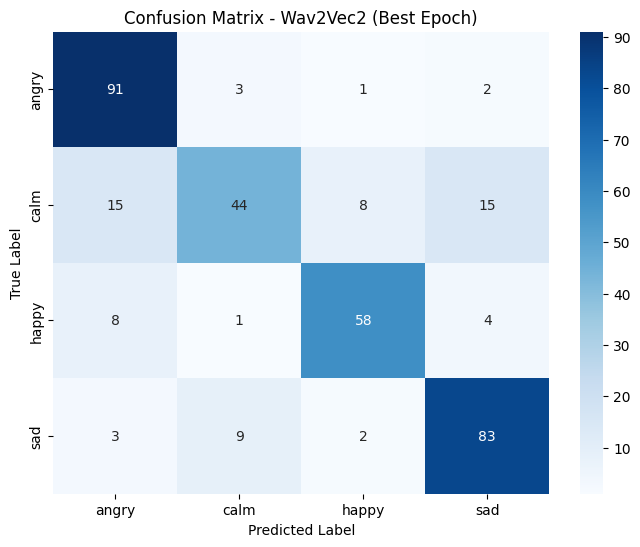

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

# الحصول على التوقعات من النموذج (يستخدم تلقائياً أفضل إيبوك)
print("جاري استخراج التوقعات لاختبار النموذج...")
predictions, labels, _ = trainer.predict(test_dataset)
preds_classes = np.argmax(predictions, axis=-1)

# طباعة تقرير الأداء المفصل
target_names = ['angry', 'calm', 'happy', 'sad']
print("\n--- Classification Report (Wav2Vec2 Best Model) ---")
print(classification_report(labels, preds_classes, target_names=target_names))

# رسم مصفوفة الارتباك
cm = confusion_matrix(labels, preds_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix - Wav2Vec2 (Best Epoch)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

In [20]:
import torch
import torch.nn as nn
from transformers import AutoModel

class MultimodalEmotionClassifier(nn.Module):
    def __init__(self, text_model_path, audio_model_path, num_labels=4):
        super(MultimodalEmotionClassifier, self).__init__()
        
        # 1. تحميل النماذج الأساسية كـ Feature Extractors (بدون رؤوس التصنيف القديمة)
        self.text_model = AutoModel.from_pretrained(text_model_path)
        self.audio_model = AutoModel.from_pretrained(audio_model_path)
        
        # تجميد أوزان النماذج الأساسية (اختياري: لتسريع التدريب وجعل التركيز فقط على تدريب رأس الدمج الجديد)
        for param in self.text_model.parameters():
            param.requires_grad = False
        for param in self.audio_model.parameters():
            param.requires_grad = False
            
        # 2. بناء رأس التصنيف المشترك
        # مصفوفة النص (768) + مصفوفة الصوت (768) = 1536
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(768 + 768, num_labels)
        
    def forward(self, input_ids, attention_mask, input_values, labels=None):
        # استخراج ميزات النص (نأخذ توكن [CLS] الذي يمثل معنى الجملة بالكامل)
        text_outputs = self.text_model(input_ids=input_ids, attention_mask=attention_mask)
        text_features = text_outputs.last_hidden_state[:, 0, :] 
        
        # استخراج ميزات الصوت (نأخذ المتوسط الحسابي لكل الإطارات الزمنية للصوت)
        audio_outputs = self.audio_model(input_values=input_values)
        audio_features = torch.mean(audio_outputs.last_hidden_state, dim=1) 
        
        # دمج الميزتين معاً (Concatenation)
        combined_features = torch.cat((text_features, audio_features), dim=1)
        
        # تمرير المصفوفة المدمجة عبر طبقة Dropout ثم طبقة التصنيف النهائية
        x = self.dropout(combined_features)
        logits = self.classifier(x)
        
        # حساب نسبة الخطأ (Loss) إذا كانت التسميات (Labels) متوفرة أثناء التدريب
        loss = None
        if labels is not None:
            loss_fct = nn.CrossEntropyLoss()
            loss = loss_fct(logits.view(-1, self.classifier.out_features), labels.view(-1))
            
        return {"loss": loss, "logits": logits}

In [24]:
import torch

# 1. تحديد مسارات النماذج
audio_model_path = "/kaggle/working/models/wav2vec2_lora_full"

# استخدام اسم النموذج الرسمي لجلب BERT التركي مباشرة عبر الإنترنت (أضمن وأسرع)
text_model_path = "dbmdz/bert-base-turkish-cased" 

print("⏳ جاري بناء وتحميل النموذج المدمج العملاق (الصوت + النص)...")
multimodal_model = MultimodalEmotionClassifier(text_model_path, audio_model_path, num_labels=4)

# 2. نقل النموذج إلى كرت الشاشة (GPU T4) لتسريع التدريب
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
multimodal_model.to(device)

print(f"✅ تم بناء النموذج المدمج بنجاح! وهو الآن يعمل على: {device}")

⏳ جاري بناء وتحميل النموذج المدمج العملاق (الصوت + النص)...


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  445MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dbmdz/bert-base-turkish-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: /kaggle/working/models/wav2vec2_lora_full
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
projector.weight  | UNEXPECTED |  | 
projector.bias    | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ تم بناء النموذج المدمج بنجاح! وهو الآن يعمل على: cuda


In [25]:
print(train_df.columns)

Index(['file_path', 'emotion', 'processed_path', 'transcription', 'label'], dtype='object')


In [26]:
from transformers import AutoTokenizer
from torch.utils.data import Dataset, DataLoader

# 1. تحميل Tokenizer لنموذج النص
tokenizer = AutoTokenizer.from_pretrained("dbmdz/bert-base-turkish-cased")

# 2. إنشاء كلاس البيانات المدمجة (Multimodal Dataset)
class EmotionMultimodalDataset(Dataset):
    def __init__(self, dataframe, tokenizer, feature_extractor, base_dir, max_text_length=128):
        self.dataframe = dataframe.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.feature_extractor = feature_extractor
        self.base_dir = base_dir
        self.max_text_length = max_text_length

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        
        # --- أولاً: معالجة النص ---
        # افترضت أن عمود النص في الـ CSV اسمه 'text'، إذا كان مختلفاً (مثلاً transcript) يرجى تعديله هنا
        text = str(row['text']) 
        text_inputs = self.tokenizer(
            text,
            max_length=self.max_text_length,
            padding='max_length',
            truncation=True,
            return_tensors="pt"
        )
        
        # --- ثانياً: معالجة الصوت ---
        path = row["processed_path"]
        parts = path.replace('\\', '/').split('/')
        folder_type = parts[-3] 
        emotion = parts[-2]     
        filename = parts[-1]    
        
        kaggle_path = f"{self.base_dir}/{folder_type}/{emotion}/{filename}"
        
        # قراءة الملف الصوتي
        y, sr = librosa.load(kaggle_path, sr=16000)
        audio_inputs = self.feature_extractor(
            y, 
            sampling_rate=16000, 
            max_length=48000, 
            truncation=True, 
            padding="max_length",
            return_tensors="pt"
        )
        
        # إرجاع القاموس المدمج
        return {
            "input_ids": text_inputs["input_ids"].squeeze(0),
            "attention_mask": text_inputs["attention_mask"].squeeze(0),
            "input_values": audio_inputs["input_values"].squeeze(0),
            "labels": torch.tensor(row["label"], dtype=torch.long)
        }

print("⏳ جاري تجهيز مصفوفات التدريب والاختبار المدمجة...")

# 3. تغليف البيانات
train_mm_dataset = EmotionMultimodalDataset(train_df, tokenizer, feature_extractor, kaggle_base_dir)
test_mm_dataset = EmotionMultimodalDataset(test_df, tokenizer, feature_extractor, kaggle_base_dir)

print(f"✅ تم تجهيز البيانات بنجاح! عدد عينات التدريب: {len(train_mm_dataset)}")

tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/251k [00:00<?, ?B/s]

⏳ جاري تجهيز مصفوفات التدريب والاختبار المدمجة...
✅ تم تجهيز البيانات بنجاح! عدد عينات التدريب: 5552


In [27]:
from transformers import AutoTokenizer
from torch.utils.data import Dataset, DataLoader
import librosa
import torch

# 1. تحميل Tokenizer لنموذج النص
tokenizer = AutoTokenizer.from_pretrained("dbmdz/bert-base-turkish-cased")

# 2. إنشاء كلاس البيانات المدمجة (Multimodal Dataset)
class EmotionMultimodalDataset(Dataset):
    def __init__(self, dataframe, tokenizer, feature_extractor, base_dir, max_text_length=128):
        self.dataframe = dataframe.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.feature_extractor = feature_extractor
        self.base_dir = base_dir
        self.max_text_length = max_text_length

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        
        # --- أولاً: معالجة النص ---
        # التعديل هنا: استخدام الكلمة الصحيحة 'transcription'
        text = str(row['transcription']) 
        text_inputs = self.tokenizer(
            text,
            max_length=self.max_text_length,
            padding='max_length',
            truncation=True,
            return_tensors="pt"
        )
        
        # --- ثانياً: معالجة الصوت ---
        path = row["processed_path"]
        parts = path.replace('\\', '/').split('/')
        folder_type = parts[-3] 
        emotion = parts[-2]     
        filename = parts[-1]    
        
        kaggle_path = f"{self.base_dir}/{folder_type}/{emotion}/{filename}"
        
        # قراءة الملف الصوتي
        y, sr = librosa.load(kaggle_path, sr=16000)
        audio_inputs = self.feature_extractor(
            y, 
            sampling_rate=16000, 
            max_length=48000, 
            truncation=True, 
            padding="max_length",
            return_tensors="pt"
        )
        
        # إرجاع القاموس المدمج
        return {
            "input_ids": text_inputs["input_ids"].squeeze(0),
            "attention_mask": text_inputs["attention_mask"].squeeze(0),
            "input_values": audio_inputs["input_values"].squeeze(0),
            "labels": torch.tensor(row["label"], dtype=torch.long)
        }

print("⏳ جاري تجهيز مصفوفات التدريب والاختبار المدمجة...")

# 3. تغليف البيانات
train_mm_dataset = EmotionMultimodalDataset(train_df, tokenizer, feature_extractor, kaggle_base_dir)
test_mm_dataset = EmotionMultimodalDataset(test_df, tokenizer, feature_extractor, kaggle_base_dir)

print(f"✅ تم تجهيز البيانات بنجاح! عدد عينات التدريب: {len(train_mm_dataset)}")

⏳ جاري تجهيز مصفوفات التدريب والاختبار المدمجة...
✅ تم تجهيز البيانات بنجاح! عدد عينات التدريب: 5552


In [28]:
from transformers import Trainer, TrainingArguments, default_data_collator
import numpy as np
import evaluate
import os

# 1. إعداد مقاييس التقييم
metric_f1 = evaluate.load("f1")
metric_acc = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    f1 = metric_f1.compute(predictions=predictions, references=labels, average="macro")["f1"]
    acc = metric_acc.compute(predictions=predictions, references=labels)["accuracy"]
    return {"macro_f1": f1, "accuracy": acc}

# 2. إعدادات التدريب للنموذج المدمج
output_dir = "/kaggle/working/multimodal_training"
os.makedirs(output_dir, exist_ok=True)

training_args = TrainingArguments(
    output_dir=output_dir,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-4, # سرعة تعلم أعلى قليلاً لأننا ندرب الرأس فقط
    per_device_train_batch_size=8, # تقليل حجم الدفعة لتجنب امتلاء ذاكرة كرت الشاشة
    per_device_eval_batch_size=8,
    num_train_epochs=10, 
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    remove_unused_columns=False, # (مهم جداً!) لمنع حذف أعمدة الصوت أو النص أثناء التدريب
    report_to="none" 
)

# 3. تجهيز الـ Trainer
trainer = Trainer(
    model=multimodal_model,
    args=training_args,
    train_dataset=train_mm_dataset,
    eval_dataset=test_mm_dataset,
    compute_metrics=compute_metrics,
    data_collator=default_data_collator
)

# 4. بدء التدريب المدمج
print("\n🚀 بدء تدريب النموذج المدمج (الصوت + النص) على Kaggle...")
trainer.train()

# 5. حفظ النموذج المدمج النهائي
final_multimodal_path = "/kaggle/working/models/turev_multimodal_final"
os.makedirs(final_multimodal_path, exist_ok=True)
torch.save(multimodal_model.state_dict(), f"{final_multimodal_path}/multimodal_weights.pth")
print(f"\n🎉 تم التدريب والحفظ بنجاح! مسار النموذج النهائي: {final_multimodal_path}")


🚀 بدء تدريب النموذج المدمج (الصوت + النص) على Kaggle...


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,No log,0.872822,0.787101,0.798271
2,0.130325,0.967236,0.794889,0.804035
3,0.032778,1.008755,0.795286,0.804035
4,0.032778,1.037732,0.790233,0.798271
5,0.032733,1.011787,0.793077,0.801153
6,0.029351,1.065393,0.792283,0.801153
7,0.029351,1.100726,0.798208,0.806916
8,0.031086,1.111963,0.794324,0.804035
9,0.033656,1.090122,0.788635,0.798271
10,0.033656,1.102434,0.788760,0.798271


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector


🎉 تم التدريب والحفظ بنجاح! مسار النموذج النهائي: /kaggle/working/models/turev_multimodal_final


جاري استخراج التوقعات لاختبار النموذج المدمج...


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]



--- Classification Report (Multimodal Fusion Model) ---
              precision    recall  f1-score   support

       angry       0.78      0.94      0.85        97
        calm       0.78      0.57      0.66        82
       happy       0.87      0.82      0.84        71
         sad       0.81      0.87      0.84        97

    accuracy                           0.81       347
   macro avg       0.81      0.80      0.80       347
weighted avg       0.81      0.81      0.80       347



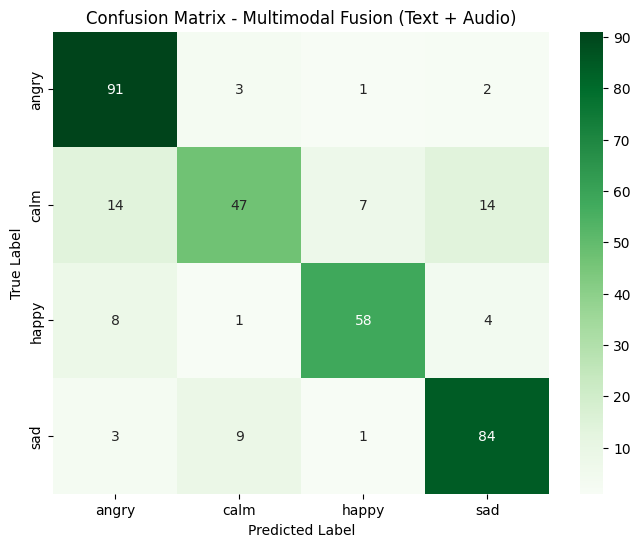

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

print("جاري استخراج التوقعات لاختبار النموذج المدمج...")
# استخدام trainer لاستخراج التوقعات (سيستخدم أفضل إيبوك تلقائياً)
predictions, labels, _ = trainer.predict(test_mm_dataset)
preds_classes = np.argmax(predictions, axis=-1)

# طباعة تقرير الأداء المفصل
target_names = ['angry', 'calm', 'happy', 'sad']
print("\n--- Classification Report (Multimodal Fusion Model) ---")
print(classification_report(labels, preds_classes, target_names=target_names))

# رسم مصفوفة الارتباك
cm = confusion_matrix(labels, preds_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', 
            xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix - Multimodal Fusion (Text + Audio)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

In [32]:
import librosa
import torch
import torch.nn.functional as F

def predict_emotion(audio_path, text, model, tokenizer, feature_extractor, device):
    # وضع النموذج في حالة التقييم (إيقاف التدريب)
    model.eval()
    
    # 1. تجهيز النص
    text_inputs = tokenizer(
        text,
        max_length=128,
        padding='max_length',
        truncation=True,
        return_tensors="pt"
    )
    # نقل مدخلات النص إلى كرت الشاشة
    input_ids = text_inputs["input_ids"].to(device)
    attention_mask = text_inputs["attention_mask"].to(device)
    
    # 2. تجهيز الصوت
    y, sr = librosa.load(audio_path, sr=16000)
    audio_inputs = feature_extractor(
        y, 
        sampling_rate=16000, 
        max_length=48000, 
        truncation=True, 
        padding="max_length",
        return_tensors="pt"
    )
    # نقل مدخلات الصوت إلى كرت الشاشة
    input_values = audio_inputs["input_values"].to(device)
    
    # 3. التوقع (بدون حساب الأوزان لتسريع العملية)
    with torch.no_grad():
        outputs = model(input_ids=input_ids, attention_mask=attention_mask, input_values=input_values)
        logits = outputs["logits"]
        
        # حساب نسبة الثقة لكل شعور (Probabilities)
        probs = F.softmax(logits, dim=-1)
        predicted_class_id = torch.argmax(logits, dim=-1).item()
        
    # خريطة المشاعر
    emotion_map_reverse = {0: 'الغضب (Angry)', 1: 'الهدوء (Calm)', 2: 'الفرح (Happy)', 3: 'الحزن (Sad)'}
    predicted_emotion = emotion_map_reverse[predicted_class_id]
    
    print("\n--- 🎯 نتيجة التحليل المدمج ---")
    print(f"النص المدخل: {text}")
    print(f"الشعور المتوقع: {predicted_emotion}")
    print(f"نسبة الثقة: {probs[0][predicted_class_id].item() * 100:.2f}%\n")

# ==========================================
# 🟢 تجربة الكود على ملف من بياناتك
# ==========================================

# خذ أي مسار لملف صوتي من مجموعة الاختبار
sample_row = test_df.iloc[30] # يمكنك تغيير الرقم لتجربة ملفات مختلفة

# بناء المسار الصحيح للملف الصوتي كما فعلنا سابقاً
path_parts = sample_row["processed_path"].replace('\\', '/').split('/')
sample_audio_path = f"{kaggle_base_dir}/{path_parts[-3]}/{path_parts[-2]}/{path_parts[-1]}"
sample_text = str(sample_row['transcription'])
true_label = sample_row['emotion']

print(f"الشعور الحقيقي في قاعدة البيانات: {true_label.upper()}")

# استدعاء دالة التوقع
predict_emotion(
    audio_path=sample_audio_path, 
    text=sample_text, 
    model=multimodal_model, 
    tokenizer=tokenizer, 
    feature_extractor=feature_extractor, 
    device=device
)

الشعور الحقيقي في قاعدة البيانات: HAPPY

--- 🎯 نتيجة التحليل المدمج ---
النص المدخل: Çepe!
الشعور المتوقع: الفرح (Happy)
نسبة الثقة: 99.98%

